# Supply Chain Demand Forecasting and Allocation

Forecast daily SKU-level demand across stores, then turn the forecast into inventory decisions (safety stock, reorder point) and a constrained allocation plan.

Run the cells top to bottom (Shift+Enter, or **Run All**). No external data or downloads needed.

## 1. Setup

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor

%matplotlib inline
print('Libraries loaded')

Libraries loaded


## 2. Generate a realistic demand dataset

Synthetic CPG sales with trend, weekly + annual seasonality, promotions, holidays and Poisson noise. To use real data (e.g. Walmart M5), just produce the same columns: `date, store, sku, units, price, promo`.

In [13]:
RNG = np.random.default_rng(42)
STORES = ['North', 'South', 'Central']
SKUS = ['SKU-A', 'SKU-B', 'SKU-C', 'SKU-D', 'SKU-E']
START, DAYS = '2023-01-01', 730
HOLIDAYS = {(12,24):1.8, (12,23):1.6, (11,24):1.7, (7,4):1.4, (2,14):1.3}

def base_level(store, sku):
    return 20 + 8*STORES.index(store) + 6*SKUS.index(sku)

def generate():
    dates = pd.date_range(START, periods=DAYS, freq='D')
    rows = []
    for store in STORES:
        for sku in SKUS:
            base = base_level(store, sku)
            trend = np.linspace(0, RNG.uniform(2, 8), DAYS)
            price0 = RNG.uniform(3, 12)
            for i, d in enumerate(dates):
                weekend = 1.25 if d.dayofweek >= 5 else 1.0
                annual = 1 + 0.20*np.sin(2*np.pi*(d.dayofyear/365.0))
                promo = 1 if RNG.random() < 0.08 else 0
                price = round(price0*(0.8 if promo else 1.0), 2)
                hol = HOLIDAYS.get((d.month, d.day), 1.0)
                mean = (base+trend[i])*weekend*annual*(1.6 if promo else 1.0)*hol
                rows.append((d, store, sku, RNG.poisson(max(mean, 0.1)), price, promo))
    return pd.DataFrame(rows, columns=['date','store','sku','units','price','promo'])

df = generate()
print('rows:', len(df))
df.head()

rows: 10950


,date,store,sku,units,price,promo
0,2023-01-01,North,SKU-A,28,6.95,0
1,2023-01-02,North,SKU-A,14,6.95,0
2,2023-01-03,North,SKU-A,28,6.95,0
3,2023-01-04,North,SKU-A,19,6.95,0
4,2023-01-05,North,SKU-A,12,6.95,0


## 3. Quick look at the data

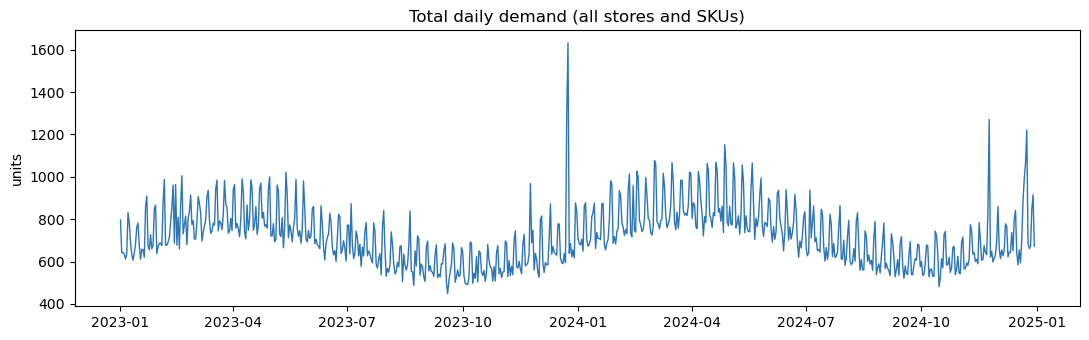

In [14]:
daily = df.groupby('date')['units'].sum()
plt.figure(figsize=(11, 3.5))
plt.plot(daily.index, daily.values, color='#2E75B6', linewidth=1)
plt.title('Total daily demand (all stores and SKUs)')
plt.ylabel('units'); plt.tight_layout(); plt.show()

## 4. Feature engineering

Calendar features, lagged demand (1/7/14/28 days), and rolling mean/std. All lags are shifted so no future information leaks into a row.

In [15]:
LAGS = [1, 7, 14, 28]; ROLLS = [7, 28]

def add_features(df):
    df = df.sort_values(['store','sku','date']).copy()
    d = pd.to_datetime(df['date'])
    df['dow'] = d.dt.dayofweek; df['month'] = d.dt.month
    df['weekofyear'] = d.dt.isocalendar().week.astype(int)
    df['is_weekend'] = (df['dow'] >= 5).astype(int)
    df['doy_sin'] = np.sin(2*np.pi*d.dt.dayofyear/365.0)
    df['doy_cos'] = np.cos(2*np.pi*d.dt.dayofyear/365.0)
    g = df.groupby(['store','sku'])['units']
    for l in LAGS: df[f'lag_{l}'] = g.shift(l)
    for w in ROLLS:
        df[f'roll_mean_{w}'] = g.transform(lambda s, w=w: s.shift(1).rolling(w).mean())
        df[f'roll_std_{w}']  = g.transform(lambda s, w=w: s.shift(1).rolling(w).std())
    df['store_id'] = df['store'].astype('category').cat.codes
    df['sku_id'] = df['sku'].astype('category').cat.codes
    return df

FEATURES = (['price','promo','dow','month','weekofyear','is_weekend','doy_sin','doy_cos','store_id','sku_id']
            + [f'lag_{l}' for l in LAGS] + [f'roll_mean_{w}' for w in ROLLS] + [f'roll_std_{w}' for w in ROLLS])

feat = add_features(df).dropna(subset=FEATURES)
feat[['date','store','sku','units'] + FEATURES].head()

,date,store,sku,units,price,promo,dow,month,weekofyear,is_weekend,...,store_id,sku_id,lag_1,lag_7,lag_14,lag_28,roll_mean_7,roll_mean_28,roll_std_7,roll_std_28
7328,2023-01-29,Central,SKU-A,45,11.47,0,6,1,4,1,...,0,0,42.0,38.0,51.0,52.0,39.285714,39.142857,2.870208,7.412274
7329,2023-01-30,Central,SKU-A,39,11.47,0,0,1,5,0,...,0,0,45.0,43.0,37.0,23.0,40.285714,38.892857,3.498299,7.072845
7330,2023-01-31,Central,SKU-A,32,11.47,0,1,1,5,0,...,0,0,39.0,35.0,35.0,37.0,39.714286,39.464286,3.302236,6.350749
7331,2023-02-01,Central,SKU-A,76,9.18,1,2,2,5,0,...,0,0,32.0,39.0,33.0,49.0,39.285714,39.285714,4.111540,6.491345
7332,2023-02-02,Central,SKU-A,39,11.47,0,3,2,5,0,...,0,0,76.0,37.0,40.0,33.0,44.571429,40.250000,14.455185,9.359586


## 5. Time-based train / test split

The last 56 days are held out for testing, so we always predict the future from the past.

In [16]:
cutoff = feat['date'].max() - pd.Timedelta(days=56)
train = feat[feat['date'] <= cutoff].copy()
test  = feat[feat['date'] >  cutoff].copy()
print('train:', train.shape, '| test:', test.shape, '| cutoff:', cutoff.date())

train: (9690, 22) | test: (840, 22) | cutoff: 2024-11-04


## 6. Baselines + Gradient Boosting

Two naive baselines (last week, 28-day moving average) versus a gradient boosting model.

In [17]:
test = test.copy()
test['pred_snaive'] = test['lag_7']
test['pred_ma28']   = test['roll_mean_28']

gbm = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05,
                                    l2_regularization=1.0, random_state=42)
gbm.fit(train[FEATURES], train['units'])
test['pred_gbm'] = gbm.predict(test[FEATURES]).clip(min=0)
print('Models trained')

Models trained


## 7. Evaluate

WMAPE and MAE/RMSE measure accuracy; Bias% shows whether we systematically over- or under-forecast.

In [18]:
def wmape(a, f):
    a, f = np.asarray(a, float), np.asarray(f, float)
    return np.abs(a - f).sum() / np.abs(a).sum()

def mae(a, f):  return float(np.mean(np.abs(np.asarray(a, float) - np.asarray(f, float))))
def rmse(a, f): return float(np.sqrt(np.mean((np.asarray(a, float) - np.asarray(f, float))**2)))
def bias_pct(a, f):
    a, f = np.asarray(a, float), np.asarray(f, float)
    return (f.sum() - a.sum()) / a.sum() * 100

def scorecard(a, f):
    return {'WMAPE': wmape(a,f), 'MAE': mae(a,f), 'RMSE': rmse(a,f), 'Bias%': bias_pct(a,f)}

rows = {}
for name, col in [('Seasonal-naive (lag 7)','pred_snaive'),
                  ('Moving average (28d)','pred_ma28'),
                  ('Gradient Boosting','pred_gbm')]:
    sub = test.dropna(subset=[col])
    rows[name] = scorecard(sub['units'], sub[col])
res = pd.DataFrame(rows).T
res.round(3)

,WMAPE,MAE,RMSE,Bias%
Seasonal-naive (lag 7),0.269,12.774,18.260,-3.573
Moving average (28d),0.208,9.859,14.715,-6.134
Gradient Boosting,0.167,7.942,11.622,-0.132


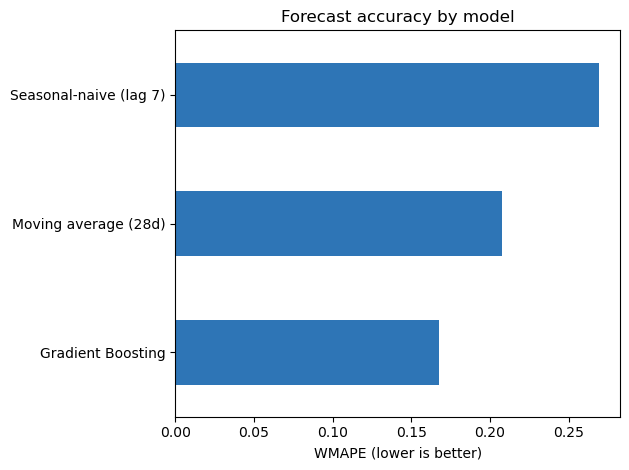

In [19]:
ax = res['WMAPE'].sort_values().plot(kind='barh', color='#2E75B6')
ax.set_xlabel('WMAPE (lower is better)'); ax.set_title('Forecast accuracy by model')
plt.tight_layout(); plt.show()

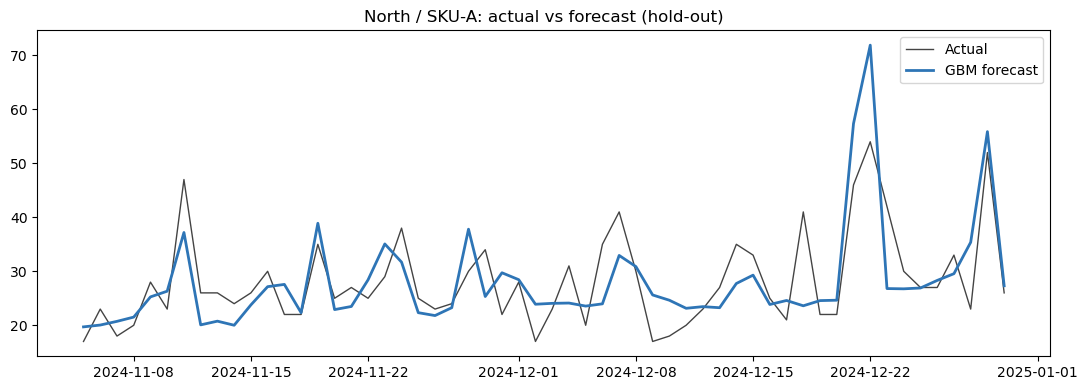

In [20]:
one = test[(test.store=='North') & (test.sku=='SKU-A')].sort_values('date')
plt.figure(figsize=(11, 4))
plt.plot(one.date, one.units, label='Actual', color='#444', linewidth=1)
plt.plot(one.date, one.pred_gbm, label='GBM forecast', color='#2E75B6', linewidth=2)
plt.legend(); plt.title('North / SKU-A: actual vs forecast (hold-out)')
plt.tight_layout(); plt.show()

## 8. Inventory economics ( EOQ, safety stock, cost)

Using the supply chain framework (Chopra & Meindl, Session 5): Economic Order Quantity, reorder point, and a safety stock that covers BOTH demand and lead-time variability via sigma_DLT = sqrt(LT*sigma_d^2 + avg^2*sL^2), at a 95% service level (z = 1.645), LT = 7 days, plus the total annual inventory cost (D/Q)*S + (Q/2 + SS)*H.

In [21]:
Z = {0.90:1.2816, 0.95:1.6449, 0.975:1.9600, 0.99:2.3263}
SERVICE, LEAD_TIME, LEAD_TIME_STD, REVIEW = 0.95, 7, 2.0, 7
ORDER_COST, HOLDING_RATE, SUPPLY_RATIO = 50.0, 0.20, 0.8
z = Z[SERVICE]

def sigma_dlt(sigma_d, avg_d, LT=LEAD_TIME, sL=LEAD_TIME_STD):
    # demand + lead-time variability (Chopra & Meindl)
    return np.sqrt(LT*sigma_d**2 + avg_d**2 * sL**2)

s = (feat.groupby(['store','sku'])
     .agg(avg_daily=('units','mean'), sigma_d=('units','std'), price=('price','mean')).reset_index())
s['sigma_DLT']       = sigma_dlt(s['sigma_d'], s['avg_daily']).round(1)
s['safety_stock']    = (z*s['sigma_DLT']).round(1)
s['reorder_point']   = (s['avg_daily']*LEAD_TIME + s['safety_stock']).round(1)
D = s['avg_daily']*365.0
H = HOLDING_RATE*s['price']
s['EOQ']             = np.sqrt(2*D*ORDER_COST/H).round(0)
s['order_up_to']     = (s['avg_daily']*(LEAD_TIME+REVIEW) + s['safety_stock']).round(1)
s['annual_inv_cost'] = ((D/s['EOQ'])*ORDER_COST + (s['EOQ']/2 + s['safety_stock'])*H).round(0)

fc = test.groupby(['store','sku'])['pred_gbm'].mean().reset_index().rename(columns={'pred_gbm':'fcst_daily'})
fc['need_LT'] = (fc['fcst_daily']*LEAD_TIME).round(1)
plan = s.merge(fc, on=['store','sku'])
plan['allocated'] = 0.0
for _, grp in plan.groupby('sku'):
    need = grp['need_LT'].sum(); supply = need*SUPPLY_RATIO
    plan.loc[grp.index,'allocated'] = (grp['need_LT']/need*supply).round(1)
plan['fill_rate_%'] = (plan['allocated']/plan['need_LT']*100).round(1)
plan[['store','sku','avg_daily','sigma_DLT','safety_stock','reorder_point','EOQ',
      'order_up_to','annual_inv_cost','need_LT','allocated','fill_rate_%']].sort_values(['sku','store']).head(9)

,store,sku,avg_daily,sigma_DLT,safety_stock,reorder_point,EOQ,order_up_to,annual_inv_cost,need_LT,allocated,fill_rate_%
0,Central,SKU-A,42.141026,91.0,149.7,444.7,826.0,739.7,2201.0,282.2,225.8,80.0
5,North,SKU-A,25.933048,56.1,92.3,273.8,832.0,455.4,1265.0,196.2,157.0,80.0
10,South,SKU-A,34.638177,74.4,122.4,364.9,813.0,607.3,1790.0,256.5,205.2,80.0
1,Central,SKU-B,50.793447,108.0,177.6,533.2,1584.0,888.7,1302.0,352.5,282.0,80.0
6,North,SKU-B,32.769231,70.4,115.8,345.2,742.0,574.6,1863.0,227.2,181.8,80.0
11,South,SKU-B,43.158120,92.3,151.8,453.9,973.0,756.0,1871.0,312.4,249.9,80.0
2,Central,SKU-C,57.145299,121.7,200.2,600.2,1317.0,1000.2,1825.0,384.3,307.4,80.0
7,North,SKU-C,38.354701,82.4,135.5,404.0,1082.0,672.5,1456.0,283.6,226.9,80.0
12,South,SKU-C,47.317664,100.9,166.0,497.2,1195.0,828.4,1647.0,333.2,266.6,80.0


## 9. Risk pooling: centralize or distribute?

 aggregating demand across locations reduces variability, so one central warehouse needs far less safety stock than the sum of separate ones. We isolate demand variability (SS = z * sigma_d * sqrt(LT)) and pool it as the square root of the sum of variances.

In [22]:
base = feat.groupby(['store','sku']).agg(avg_daily=('units','mean'), sigma_d=('units','std')).reset_index()
base['ss_store'] = z*base['sigma_d']*np.sqrt(LEAD_TIME)
rows = []
for sku, g in base.groupby('sku'):
    ss_dec = g['ss_store'].sum()
    sigma_pool = np.sqrt((g['sigma_d']**2).sum())
    ss_cen = z*sigma_pool*np.sqrt(LEAD_TIME)
    rows.append((sku, round(ss_dec,1), round(ss_cen,1), round((1-ss_cen/ss_dec)*100,1)))
pool = pd.DataFrame(rows, columns=['sku','ss_decentralized','ss_centralized','reduction_%'])
print('Overall safety-stock reduction from pooling: %.1f%%' % ((1 - pool.ss_centralized.sum()/pool.ss_decentralized.sum())*100))
pool

Overall safety-stock reduction from pooling: 41.7%


,sku,ss_decentralized,ss_centralized,reduction_%
0,SKU-A,136.7,80.3,41.2
1,SKU-B,156.7,91.4,41.7
2,SKU-C,176.2,102.7,41.7
3,SKU-D,196.2,114.3,41.7
4,SKU-E,228.0,132.8,41.8


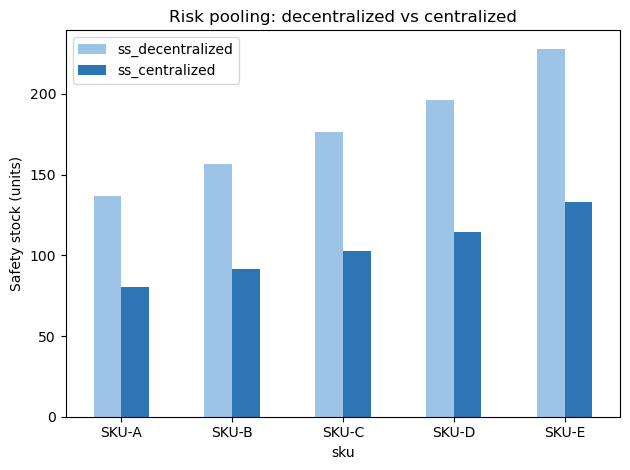

In [23]:
ax = pool.set_index('sku')[['ss_decentralized','ss_centralized']].plot(kind='bar', color=['#9DC3E6','#2E75B6'])
ax.set_ylabel('Safety stock (units)'); ax.set_title('Risk pooling: decentralized vs centralized')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 10. Takeaways

- Gradient Boosting beats both naive baselines on WMAPE with near-zero bias.
- The forecast drives a full inventory policy: EOQ, reorder point, safety stock (demand + lead-time variability) and total inventory cost.
- Centralizing the three stores into one DC cuts safety stock by about 42%.
- Proportional fair-share gives every store the same fill rate when supply is short.
